# 01 펌프 데이터 파일 구조와 결측치 진단

**진행 순서**

1. 파일 구조 확인
2. 결측치 확인 및 처리 방침 결정
3. 라벨 파생
4. 센서 분포·고장 전후·상관관계 EDA

이번 노트북은 **1단계와 2단계**를 다룹니다. 입력은 저장소의 `data/sensor.csv`이며, 압축 상태라면 `data/archive.zip`을 사용할 수 있습니다. `pandas`, `matplotlib`가 설치된 Python 커널에서 위에서부터 실행하세요.

## 1. 파일 구조 확인

### 1-1. 원본 파일 불러오기

저장소 최상위나 `notebooks/`에서 실행할 수 있습니다. 경로는 기존 결측 진단 모듈과 같은 기준으로 찾습니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 현재 작업 폴더에서 위로 올라가며 팀 저장소를 찾습니다.
current_dir = Path.cwd()
project_root = next(
    (
        folder for folder in (current_dir, *current_dir.parents)
        if (folder / "src" / "pump_missingness_audit.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소나 notebooks 폴더에서 커널을 실행하세요.")

sys.path.insert(0, str(project_root))
from src.pump_missingness_audit import (
    SPLIT_DATES, SPLIT_NAMES, audit_missingness, default_source, read_sensor_data,
)

source = default_source()
raw = read_sensor_data(source)
sensor_columns = [column for column in raw if column.startswith("sensor_")]
print(f"입력 파일: {source.relative_to(project_root).as_posix()}")
print(f"원본 {len(raw):,}행 × {len(raw.columns)}열 · 센서 {len(sensor_columns)}개")
display(raw.loc[:, ["timestamp", *sensor_columns[:4], "machine_status"]].head(4))

입력 파일: data/sensor.csv
원본 220,320행 × 55열 · 센서 52개


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,machine_status
0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,NORMAL
1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,NORMAL
2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,NORMAL
3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,NORMAL


### 1-2. 열의 역할과 시간축 확인

행 번호는 원본 대조에 사용합니다. `timestamp`는 시간 순서를, `machine_status`는 원본 설비 상태를 확인하는 열입니다. 시각 자체가 빠진 경우와 센서값이 비어 있는 경우를 구분합니다.

In [ ]:
timestamps = pd.to_datetime(raw["timestamp"], errors="coerce")
ordered_times = timestamps.dropna().sort_values()
missing_timestamps = len(pd.date_range(ordered_times.iloc[0], ordered_times.iloc[-1], freq="min"))
missing_timestamps -= ordered_times.nunique()

schema = pd.DataFrame({
    "열": ["timestamp", "machine_status", "sensor_*", "그 외"],
    "자료형": [
        str(raw["timestamp"].dtype),
        str(raw["machine_status"].dtype),
        ", ".join(sorted({str(raw[column].dtype) for column in sensor_columns})),
        ", ".join(str(raw[column].dtype) for column in raw if column not in [*sensor_columns, "timestamp", "machine_status"]),
    ],
    "열 수": [1, 1, len(sensor_columns), len(raw.columns) - len(sensor_columns) - 2],
})
display(schema)
print(f"기록 기간: {ordered_times.iloc[0]} ~ {ordered_times.iloc[-1]}")
print(f"파싱 불가 {timestamps.isna().sum():,}행 · 중복 {timestamps.dropna().duplicated().sum():,}행 · 시각 누락 {missing_timestamps:,}분")
display(raw["machine_status"].value_counts(dropna=False).to_frame("원본 상태별 행 수"))

,열,자료형,열 수
0,timestamp,str,1
1,machine_status,str,1
2,sensor_*,float64,52
3,그 외,int64,1


기록 기간: 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00
파싱 불가 0행 · 중복 0행 · 시각 누락 0분


,원본 상태별 행 수
machine_status,
NORMAL,205836
RECOVERING,14477
BROKEN,7


## 2. 결측치 확인 및 처리 방침 결정

### 2-1. 전체 센서가 비어 있는 행 찾기

원본 시각, CSV 레코드 번호, 첫 번째 열의 원본 행 번호를 함께 확인합니다. CSV 레코드 번호에는 헤더 한 줄이 포함됩니다.

In [ ]:
# 기존 진단 모듈에서 요약과 상세 표를 가져옵니다.
report = audit_missingness(source, min_gap=60)
display(report["all_missing_rows"])
display(report["by_split_status"])

,CSV 레코드 번호,원본 행 번호,split,machine_status
timestamp,,,,
2018-04-27 17:48:00,38510,38508,train,NORMAL
2018-04-27 17:49:00,38511,38509,train,NORMAL
2018-04-27 17:50:00,38512,38510,train,NORMAL
2018-04-27 17:51:00,38513,38511,train,NORMAL
2018-04-27 17:52:00,38514,38512,train,NORMAL
2018-04-27 17:53:00,38515,38513,train,NORMAL
2018-04-27 17:54:00,38516,38514,train,NORMAL
2018-04-27 17:55:00,38517,38515,train,NORMAL
2018-07-11 09:12:00,145994,145992,test,NORMAL


전체 행  센서 전체 결측  일부 결측(전 구간 결측 센서 제외)
split 상태                                               
train BROKEN          4         0                     0
      NORMAL      81865         8                   337
      RECOVERING   5971         0                  4588
valid BROKEN          1         0                     1
      NORMAL      40569         0                 12419
      RECOVERING   8390         0                  6849
test  BROKEN          2         0                     1
      NORMAL      83402         3                 76936
      RECOVERING    116         0                    75

### 2-2. 센서별 장기 결측 확인

표의 `train`, `valid`, `test`는 각 분할의 결측 행 수입니다. 장기 결측 상세 표는 60분 이상인 구간 중 가장 긴 12개를 보여줍니다. 그래프는 전체가 결측인 센서를 제외하고 최장 공백을 일 단위로 비교합니다.

,결측 건수,결측률(%),train,valid,test,최장 결측(분)
sensor_15,220320,100.000,87840,48960,83520,220320
sensor_50,77017,34.957,17,4,76996,76996
sensor_51,15383,6.982,17,15360,6,15356
sensor_00,10208,4.633,4122,6080,6,6076
sensor_07,5451,2.474,773,4672,6,4668
sensor_08,5107,2.318,710,4391,6,4227
sensor_06,4798,2.178,246,4546,6,4299
sensor_09,4595,2.086,9,4580,6,4212
sensor_01,369,0.167,64,4,301,200
sensor_30,261,0.118,255,1,5,239


,센서,시작,종료,연속 결측(분)
0,sensor_15,2018-04-01 00:00:00,2018-08-31 23:59:00,220320
1,sensor_50,2018-07-09 12:44:00,2018-08-31 23:59:00,76996
2,sensor_51,2018-06-20 07:58:00,2018-06-30 23:53:00,15356
3,sensor_00,2018-06-29 09:19:00,2018-07-03 14:34:00,6076
4,sensor_07,2018-06-30 09:18:00,2018-07-03 15:05:00,4668
5,sensor_06,2018-06-30 15:27:00,2018-07-03 15:05:00,4299
6,sensor_08,2018-06-30 15:45:00,2018-07-03 14:11:00,4227
7,sensor_09,2018-06-30 16:00:00,2018-07-03 14:11:00,4212
8,sensor_00,2018-04-18 00:31:00,2018-04-20 04:13:00,3103
9,sensor_00,2018-04-12 22:00:00,2018-04-13 13:15:00,916


findfont: Failed to find font weight semibold, now using 700.


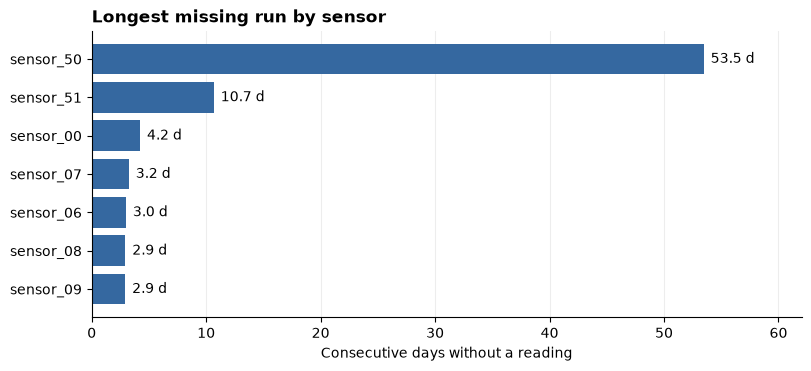

In [ ]:
sensor_missing = report["by_sensor"]
display(sensor_missing.head(12).round(3))
display(report["long_gaps"].loc[:, ["센서", "시작", "종료", "연속 결측(분)"]].head(12))

gap_days = (
    sensor_missing.loc[sensor_missing["결측률(%)"].lt(100), "최장 결측(분)"]
    .nlargest(7)
    .div(1440)
    .sort_values()
)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bars = ax.barh(gap_days.index, gap_days, color="#3568a0")
ax.bar_label(bars, fmt="%.1f d", padding=5)
ax.set_xlim(0, max(gap_days.max() * 1.16, 1))
ax.set_title("Longest missing run by sensor", loc="left", fontweight="semibold")
ax.set_xlabel("Consecutive days without a reading")
ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 2-3. 49개 센서와 44개 센서의 관측 범위 비교

최근 15분 중 실제 관측값이 12개 이상인 센서를 세고, 전체 센서의 90% 이상이 이 조건을 충족한 행을 집계합니다. 현재 행의 센서값이 전부 비어 있으면 통과에서 제외합니다. 이 수치는 **결측 처리 방침을 정하기 위한 가용성 비교**입니다.

In [ ]:
# 원본을 분 단위 시간축에 맞춰 공백이 있는 경우에도 15행이 15분이 되도록 합니다.
ordered = raw.assign(timestamp=timestamps).set_index("timestamp").sort_index()
timeline = ordered.asfreq("min")
split = pd.cut(ordered.index, pd.to_datetime(SPLIT_DATES), labels=SPLIT_NAMES, right=False)

base_excluded = {"sensor_15", "sensor_50", "sensor_51"}
extra_excluded = {"sensor_00", "sensor_06", "sensor_07", "sensor_08", "sensor_09"}
sensor_sets = {
    "49개 기준 통과": [name for name in sensor_columns if name not in base_excluded],
    "44개 기준 통과": [
        name for name in sensor_columns if name not in base_excluded | extra_excluded
    ],
}

coverage = pd.DataFrame({"분할": split, "원본 상태": ordered["machine_status"], "원본 행": 1})
for name, columns in sensor_sets.items():
    observed = timeline[columns].notna()
    sensor_ready = observed.rolling(window=15, min_periods=12).sum().ge(12)
    usable = sensor_ready.mean(axis=1).ge(0.90) & observed.any(axis=1)
    coverage[name] = usable.reindex(ordered.index)

coverage_summary = coverage.groupby(["분할", "원본 상태"], observed=True).sum()
display(coverage_summary)

원본 행  49개 기준 통과  44개 기준 통과
분할    원본 상태                                  
train BROKEN          4          4          4
      NORMAL      81865      81830      81830
      RECOVERING   5971       5971       5971
valid BROKEN          1          1          1
      NORMAL      40569      40558      40558
      RECOVERING   8390       4002       8390
test  BROKEN          2          2          2
      NORMAL      83402      83399      83399
      RECOVERING    116        116        116

### 2-4. 전처리 방침

- **시간축 유지** — 전체 결측 11행은 원본 시계열에 관측 불가로 표시합니다. 시계열 특징 계산을 끝낸 뒤 모델용 CSV에서 해당 행을 제외합니다.
- **첫 모델 입력** — `sensor_15`, `sensor_50`, `sensor_51`과 복구 구간에 장기 결측이 집중된 `sensor_00`, `sensor_06`~`sensor_09`를 제외한 **44개 센서**를 사용합니다. 이 구성은 전체 기간의 결측 양상을 확인한 뒤 정한 첫 실험 기준입니다.
- **짧은 공백** — 직전 관측값을 최대 3분까지만 이어 쓰고, 그 이후는 결측으로 표시합니다. 전체 센서 결측 행은 따로 관측 불가로 유지합니다.
- **모델에 전달할 특징** — 관측 기준을 통과한 행에서 계산된 특징 일부가 여전히 비어 있다면 학습 구간의 특징별 중앙값으로 채웁니다. 제외·대체 건수와 기준은 `analysis_config.json`에 기록합니다.

관측 기준을 적용했을 때 검증 구간의 `RECOVERING` 8,390행 중 **49개 구성은 4,002행, 44개 구성은 8,390행**이 통과했습니다. 다음 단계에서 실제 전처리를 적용한 뒤 분할별·상태별 표본 수를 다시 집계합니다.